# Figure 5: Sensitivity Analysis for Projected Discharge


In [1]:
file ='../Figures'

import pandas as pd
import numpy as np

import os

# function that creates dataframe from list of files in a path
def create_dataframe(path, tag):
# get all files in the path
    files = os.listdir(path)

    # create a dictionary to store all dataframes
    dfs = {}

    for file in files:
        if file.endswith('.csv') and 'cost' not in file:
            # read the csv file
            df = pd.read_csv(path+file)

            # if file includes tag in name
            if tag in file:
                # create string with only the characters before "_summary.csv"
                mult = file.split('_summary.csv')[0]
                try:
                    mult = mult.split(tag)[1]
                    dfs[mult] = df
                except IndexError:
                    dfs = df                
    
    return dfs


def create_dataframe_computational_cost(path, tag):
    files = os.listdir(path)

    dfs = {}

    for file in files:
        if file.endswith('.csv') and 'computational_cost' in file:
            df = pd.read_csv(path+file)

            if tag in file:
                mult = file.split('_computational_cost.csv')[0]
                try:
                    mult = mult.split(tag)[1]
                    dfs[mult] = df
                except IndexError:
                    dfs = df                
    
    return dfs

# function that creates a dataframe with the data of a specific WWTP
def create_df(WWTP, dfs):
    df = pd.DataFrame(index=sorted(dfs.keys()))
    for key in sorted(dfs.keys()):
        df_small = dfs[key].loc[dfs[key]['Abbreviation'] == WWTP]
        for column in df_small.columns:
            # add the value to Palo_Alto data with the column being the key and the row is the column name
            df.loc[key, column] = df_small[column].values[0]
    return df

# function that creates a dataframe for total values
def create_df_total(dfs):
    df = pd.DataFrame(index=sorted(dfs.keys()))
    for key in sorted(dfs.keys()):
        df_small = dfs[key].loc[dfs[key]['Abbreviation'] == 'Total']
        for column in df_small.columns:
            df.loc[key, column] = df_small[column].values[0]
    return df

## Plot sensitivity analysis of total cost 

In [2]:
# plot total cost of the three different dataframes as a function of the key
import matplotlib.pyplot as plt

def plot_total_cost(WWTPs, dfs, title):
    colors = ['green', 'red', 'purple', 'black', 'yellow', 'pink', 'brown', 'grey']
    hfont = {'fontname':'Helvetica', 'size':12}
    hfont_ticks = {'fontname':'Helvetica', 'size':10}

    fig,ax = plt.subplots(figsize=(10, 4))
    for i,WWTP in enumerate(WWTPs):
        df = create_df(WWTP, dfs)
        per = [float(ind)*100 - 100 for ind in df.index]
        ticks = [per[a] for a in range(0, len(per), 5)]
        #per = [str(round(float(ind)*100 - 100,4)) + '%' for ind in df.index]
        #ticks = [str(round(float(ind)*100 - 100)) + '%' for ind in df.index]
        plt.plot(per, df['Total_cost'], label=WWTP, marker='o', color=colors[i])
    
    total_cost = sum([create_df(WWTP, dfs)['Total_cost'] for WWTP in WWTPs])
    plt.plot(per, total_cost, label='Total', marker='x', color='black', linestyle='--')
    
    # add dashed vertical line at 0% variation
    #plt.axvline(x=0, color='black', linestyle='--')
        
    
    ax.set_xticks(ticks, [str(round(tick)) + '%' for tick in ticks], **hfont_ticks)
    ax.set_xlabel('Percent change in projected discharge for each WWTP', **hfont)

    # add a secondary x-axis
    df = create_df_total(dfs)
    
    secax = ax.secondary_xaxis('top')
    ticks_2 = [round(df.Total_removal[a]*10**-3) for a in range(0, len(per), 5)]
    secax.set_xticks(ticks, ticks_2, **hfont)
    secax.set_xlabel('TIN removed in the subembayment (1,000 lb N)', **hfont)


    plt.legend(prop = {'family':'Helvetica', 'size':10})
    plt.ylabel(title + ' total NPV cost ($million)', **hfont)
    plt.tight_layout()
    plt.show()
    
    return fig, ax

# plot individual costs
def plot_individual_costs (WWTPs, dfs, plot_tag):
    colors = ['green', 'red', 'purple', 'black', 'yellow', 'pink', 'brown', 'grey']
    hfont = {'fontname':'Helvetica', 'size':12}
    capex_col = ['SS_capex_NPV', 'L2_capex_NPV', 'L2upg3_capex_NPV', 'L3_capex_NPV']
    opex_col = ['SS_opex_NPV', 'L2_opex_NPV', 'L2upg3_opex_NPV', 'L3_opex_NPV']
    labels = ['SS', 'L2', 'L2upg3', 'L3']
    
    #create figure with 3 subplots
    fig, axs = plt.subplots(len(WWTPs), 1, figsize=(10, 10))
    for i,WWTP in enumerate(WWTPs):
        df = create_df(WWTP, dfs)
        per = [float(ind)*100 - 100 for ind in df.index]
        ticks = [per[a] for a in range(0, len(per), 5)]
        #per = [str(round(float(ind)*100 - 100,4)) + '%' for ind in df.index]

        for j,column in enumerate(capex_col):
            if plot_tag == 'total':
                value = df[capex_col[j]] + df[opex_col[j]] 
                axs[i].set_ylabel('Total NPV cost ($million)', **hfont)
            elif plot_tag == 'capex':
                value = df[capex_col[j]] 
                axs[i].set_ylabel('NPV Capex ($million)', **hfont)
            elif plot_tag == 'opex':
                value = df[opex_col[j]] 
                axs[i].set_ylabel('NPV Opex ($mil/yr)', **hfont)
            
            axs[i].plot(per, value, label=labels[j], marker='o', color=colors[j])
            axs[i].set_title(WWTP)
            axs[i].set_xticks(ticks, [str(round(tick)) + '%' for tick in ticks])
            axs[i].legend()
    
    plt.xlabel('Percent change in projected discharge for each WWTP', **hfont)
    
    plt.tight_layout()
    plt.show()
    
    return fig, axs

### Create dataframes for all cases 

In [3]:
path = '../Results/Sensitivity_all_coordination_S/'
WWTPS = ['Palo Alto', 'SJSC', 'Sunnyvale']

dfs_SNC = create_dataframe(path, 'No_coordination_')
dfs_SPC = create_dataframe(path, 'Partial_coordination_')
dfs_SFC = create_dataframe(path, 'Full_coordination_')
dfs_SFC_10_yr = create_dataframe(path, 'Full_10yr_coordination__')

In [4]:
path = '../Results/Sensitivity_all_coordination_NS/'
WWTPS = ['Palo Alto', 'SJSC', 'Sunnyvale']

dfs_NSNC = create_dataframe(path, 'No_coordination_')
dfs_NSPC = create_dataframe(path, 'Partial_coordination_')
dfs_NSFC = create_dataframe(path, 'Full_coordination_')

### Create daraframes for total costs of each case

In [5]:
df_total_SNC = create_df_total(dfs_SNC)
df_total_SPC = create_df_total(dfs_SPC)
df_total_SFC = create_df_total(dfs_SFC)
df_total_SFC_10 = create_df_total(dfs_SFC_10_yr)

In [6]:
df_total_NSNC = create_df_total(dfs_NSNC)
df_total_NSPC = create_df_total(dfs_NSPC)
df_total_NFC = create_df_total(dfs_NSFC)

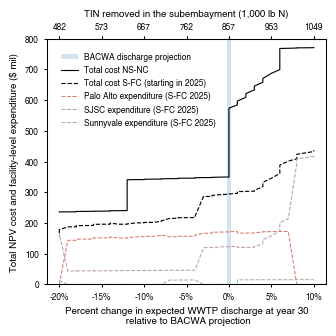

In [7]:

import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator


markers = ['o', 'd', 's']
labels = ['SS', 'L2', 'L2upg3', 'L3']
colors = ['#D57A6E', '#B79BB8', '#A3B89C']
hfont = {'fontname':'Helvetica', 'size':7}
hfont_ticks = {'fontname':'Helvetica', 'size':6}
leg_size = 6
line_wid = 0.75
bord_wid = 2
m_size = 3.5
ling_fig_wid = 0.75

#create figure with 4 subplots
fig, axs = plt.subplots(1, 1, figsize=(88/25.4, 88/25.4))

# Plot total costs for SNC
WWTPs = ['Palo Alto', 'SJSC', 'Sunnyvale']

for i,WWTP in enumerate(WWTPs):
    df = create_df(WWTP, dfs_SFC)
    per = [round(float(ind)*100 - 100) for ind in df.index]
    ticks = [per[a] for a in range(0, len(per), 10)]

axs.axvspan(-0.25, 0.25, alpha=0.2, label = 'BACWA discharge projection')

total_cost_NSNC = sum([create_df(WWTP, dfs_NSNC)['Total_cost'] for WWTP in WWTPs])

axs.plot(per, total_cost_NSNC, label='Total cost NS-NC', color='black', linestyle='-', linewidth=ling_fig_wid*1.1, markersize=m_size)
'''
total_cost_NSPC = sum([create_df(WWTP, dfs_NSPC)['Total_cost'] for WWTP in WWTPs])
axs.plot(per, total_cost_NSPC, label='Total cost NS-PC', color='black', linestyle=':', linewidth=ling_fig_wid, markersize=m_size)
'''
total_cost_SPC = sum([create_df(WWTP, dfs_SPC)['Total_cost'] for WWTP in WWTPs])
#axs.plot(per, total_cost_SPC, label='Total cost S-PC', color='black', linestyle=':', linewidth=ling_fig_wid, markersize=m_size)

total_cost_SFC = sum([create_df(WWTP, dfs_SFC)['Total_cost'] for WWTP in WWTPs])
axs.plot(per, total_cost_SFC, label='Total cost S-FC (starting in 2025)', color='black', linestyle='--', linewidth=ling_fig_wid*1.1, markersize=m_size)


for i,WWTP in enumerate(WWTPs):
    df = create_df(WWTP, dfs_SFC)
    per = [round(float(ind)*100 - 100) for ind in df.index]
    ticks = [per[a] for a in range(0, len(per), 10)]
    axs.plot(per, df['Total_cost'].values, label=WWTP + ' expenditure (S-FC 2025)', color=colors[i], linestyle= '--', linewidth=ling_fig_wid, markersize=m_size)




## add a secondary x-axis
df = create_df_total(dfs_SFC)
secax = axs.secondary_xaxis('top')
ticks_2 = [round(df.Total_removal.iloc[a]*10**-3) for a in range(0, len(per), 10)]
secax.set_xticks(ticks, ticks_2, **hfont)
secax.set_xlabel('TIN removed in the subembayment (1,000 lb N)', **hfont)
axs.set_ylabel('S-NC Total Cost\n(NPV $mil)', **hfont)
axs.legend(prop = {'family':'Helvetica', 'size':leg_size}, loc='upper left', frameon=False, bbox_to_anchor=(0.025, 0.975), ncol = 1)


secax.tick_params(axis='both', which='major', labelsize=leg_size, labelfontfamily= 'Helvetica', width=line_wid, length=bord_wid)
secax.spines["top"].set_linewidth(line_wid)




axs.xaxis.set_ticks_position('both')
for spine in axs.spines.values():
    spine.set_linewidth(line_wid)  # Adjust thickness (default is ~1.0)


plt.ylim([0, 800])

plt.xticks(ticks, [str(round(tick)) + '%' for tick in ticks]) 
axs.set_xlabel('Percent change in expected WWTP discharge at year 30\n relative to BACWA projection', **hfont)
plt.ylabel('Total NPV cost and facility-level expenditure ($ mil)', **hfont)
axs.tick_params(axis="both", which='major', labelfontfamily= 'Helvetica', width=line_wid, length=bord_wid, labelsize=leg_size)


fig.tight_layout()
fig.savefig(file + "/Fig_4.svg", format="svg", dpi=300)

## Sensitivity plot of cost-optimal treatment construction vs varying discharge projections

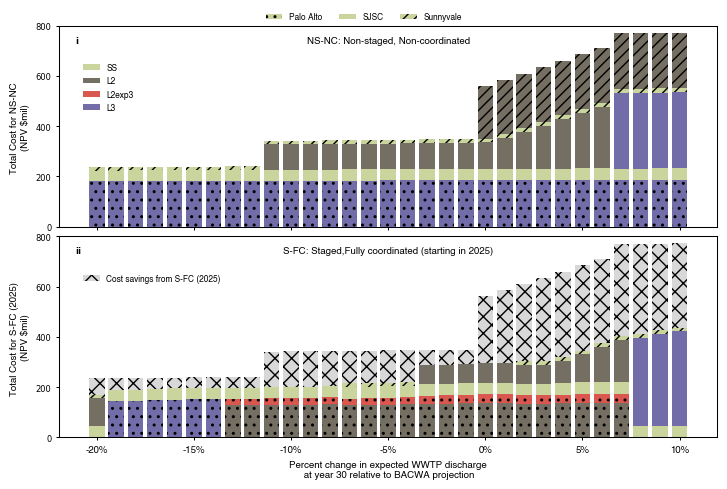

In [8]:
WWTPs = ['Palo Alto', 'SJSC', 'Sunnyvale']

colors = {'L3': '#726DA8', 'L2': '#746F62', 'SS': '#CAD49D', 'L2upg3': '#D9574F', 'total': '#EB5E28', 'required': '#8EA8C3'}
capex_col = ['SS_capex_NPV', 'L2_capex_NPV', 'L2upg3_capex_NPV', 'L3_capex_NPV']
opex_col = ['SS_opex_NPV', 'L2_opex_NPV', 'L2upg3_opex_NPV', 'L3_opex_NPV']
labels = ['SS', 'L2', 'L2upg3', 'L3']
hatch_style = ['..','','///']


desired_indices = df_total_SNC.index.tolist()[::2]


hfont = {'fontname':'Helvetica', 'size':7}
hfont_ticks = {'fontname':'Helvetica', 'size':6}
lab_size = 7
leg_size = 6
line_wid = 0.75
bord_wid = 2
m_size = 2.5

#create figure with 4 subplots

fig, axs = plt.subplots(2, 1, figsize=(180/25.4, 120/25.4))

# Plot Case 2: non-coordinated
cost_savings_full = df_total_NSNC.loc[desired_indices]['Total_cost'] - df_total_SFC.loc[desired_indices]['Total_cost']

cumval = 0
for i,WWTP in enumerate(WWTPs):
    dfs = dfs_NSNC
    df = create_df(WWTP, dfs)
    df = df.loc[desired_indices]
    per = [float(ind)*100 - 100 for ind in df.index]
    ticks = [per[a] for a in range(0, len(per), 5)]
    upgrades = pd.DataFrame()
    for L,column in enumerate(capex_col):
        upgrades[labels[L]] = df[capex_col[L]] + df[opex_col[L]]
        if WWTP == 'SJSC':
            axs[0].bar(per, upgrades[labels[L]], label =WWTP + labels[L], color=colors[labels[L]], hatch = hatch_style[i], bottom = cumval)
        else:
            axs[0].bar(per, upgrades[labels[L]], label = '', color=colors[labels[L]], hatch = hatch_style[i], bottom = cumval)
        cumval = cumval + upgrades[labels[L]]

# Plot Case 4: fully coordinated
cumval = 0
for i,WWTP in enumerate(WWTPs):
    dfs = dfs_SFC
    df = create_df(WWTP, dfs)
    df = df.loc[desired_indices]
    per = [float(ind)*100 - 100 for ind in df.index]
    for L,column in enumerate(capex_col):
        upgrades[labels[L]] = df[capex_col[L]] + df[opex_col[L]]
        axs[1].bar(per, upgrades[labels[L]], label = WWTP + labels[L], color=colors[labels[L]], hatch = hatch_style[i], bottom = cumval)
        cumval = cumval + upgrades[labels[L]]

axs[1].bar(per, cost_savings_full, label = 'Cost savings from S-FC', color='grey', alpha = 0.3, bottom = cumval, hatch = 'xx')

#axs[0].legend(prop = {'family':'Helvetica', 'size':leg_size}, loc='upper left', frameon=False, bbox_to_anchor=(0, 0.85))
axs[0].set_xticks(ticks, [str(round(tick)) + '%' for tick in ticks], **hfont_ticks)
axs[0].set_xticklabels([])
axs[0].set_xlabel('')
axs[0].set_ylabel('Total Cost for NS-NC \n(NPV $mil)', **hfont)


axs[1].set_ylabel('Total Cost for S-FC (2025) \n(NPV $mil)', **hfont)
axs[1].set_xticks(ticks, [str(round(tick)) + '%' for tick in ticks], **hfont_ticks)
axs[1].set_xlabel('Percent change in expected WWTP discharge\n at year 30 relative to BACWA projection', **hfont)

handles, labels = axs[0].get_legend_handles_labels()
selected_labels = ['SJSCSS', 'SJSCL2', 'SJSCL2upg3', 'SJSCL3']
selected_handles = [handles[labels.index(lbl)] for lbl in selected_labels]

axs[0].legend(
    selected_handles,
    ['SS', 'L2', 'L2exp3', 'L3', 'Cost savings from S-FC (2025)'],
    loc="upper left",    # Position the legend at the top center
    bbox_to_anchor=(0.025, 0.85),  # Fine-tune the position above the figure
    ncol=1,                # Display items in a single row
    prop={'family':'Helvetica', 'size':leg_size},  # Set font to Helvetica
    frameon=False
)

handles, labels = axs[1].get_legend_handles_labels()
selected_labels = ['Cost savings from S-FC']
selected_handles = [handles[labels.index(lbl)] for lbl in selected_labels]

axs[1].legend(
    selected_handles,
    ['Cost savings from S-FC (2025)'],
    loc="upper left",    # Position the legend at the top center
    bbox_to_anchor=(0.025, 0.85),  # Fine-tune the position above the figure
    ncol=1,                # Display items in a single row
    prop={'family':'Helvetica', 'size':leg_size},  # Set font to Helvetica
    frameon=False
)



handles, labels = axs[1].get_legend_handles_labels()
selected_labels = ['Palo AltoSS', 'SJSCSS', 'SunnyvaleSS']
selected_handles = [handles[labels.index(lbl)] for lbl in selected_labels]

fig.legend(
    selected_handles,
    ['Palo Alto', 'SJSC', 'Sunnyvale'],
    loc="upper center",    # Position the legend at the top center
    bbox_to_anchor=(0.5, 1.005),  # Fine-tune the position above the figure
    ncol=3,                # Display items in a single row
    prop={'family':'Helvetica', 'size':leg_size},  # Set font to Helvetica
    frameon=False
)
fig_labels = ['i', 'ii']
title = ['NS-NC: Non-staged, Non-coordinated', 'S-FC: Staged,Fully coordinated (starting in 2025)']
for i,ax in enumerate(axs):
    ax.text(0.025, 0.95, fig_labels[i], transform=ax.transAxes, fontsize=leg_size, fontweight='bold', va='top', ha='left')
    ax.text(0.5, 0.95, title[i], transform=ax.transAxes, fontsize=lab_size, va='top', ha='center', fontname='Helvetica')
    ax.tick_params(axis="both", width=line_wid, length=bord_wid, labelsize=leg_size)
    ax.tick_params(axis='x', labelsize=lab_size)
    ax.set_ylim([0, 800])
    ax.set_yticks(range(0, 801, 200))

    for spine in ax.spines.values():
        spine.set_linewidth(line_wid)  # Adjust thickness (default is ~1.0)

fig.tight_layout(pad=0.05, rect=[0, 0, 1, 0.97])
fig.savefig(file + "/SI/S8.svg", format="svg", bbox_inches='tight', dpi=300)

# Sensitivity plots for model assumptions

In [9]:
path_TR_S= '../Results/Sensitivity_all_coordination_TR_S/'
path_TR_NS = '../Results/Sensitivity_all_coordination_TR_NS/'
path_power_S = '../Results/Power_law_S/'
path_power_NS = '../Results/Power_law_NS/'
path_exp_S = '../Results/Exponential_projection_S/'
path_exp_NS = '../Results/Exponential_projection_NS/'
WWTPS = ['Palo Alto', 'SJSC', 'Sunnyvale']

df_base = { }
dfs_TR_3 = {}
dfs_power = {}
dfs_exp = {}

for staged in ['SFC', 'NSNC']:
    df_base[staged] = create_dataframe(path_TR_S if staged == 'SFC' else path_TR_NS, 'Full_coordination_')["1.0"]
    dfs_TR_3[staged] = create_dataframe(path_TR_S if staged == 'SFC' else path_TR_NS, 'Full_coordination_')["3.0"]
    dfs_power[staged] = create_dataframe(path_power_S if staged == 'SFC' else path_power_NS, 'Full_coordination_')
    dfs_exp[staged] = create_dataframe(path_exp_S if staged == 'SFC' else path_exp_NS, 'Full_coordination_')



TR: 1.0, Total cost: 294.1036974131887, percent increase: 0.0%
TR: 1.5, Total cost: 310.4977644693116, percent increase: 5.6%
TR: 2.0, Total cost: 314.30909141875924, percent increase: 6.9%
TR: 2.5, Total cost: 315.33247432590827, percent increase: 7.2%
TR: 3.0, Total cost: 317.96477867463415, percent increase: 8.1%


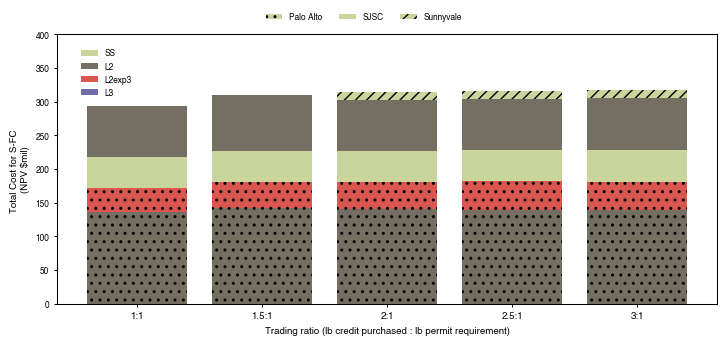

In [13]:
WWTPs = ['Palo Alto', 'SJSC', 'Sunnyvale']

colors = {'L3': '#726DA8', 'L2': '#746F62', 'SS': '#CAD49D', 'L2upg3': '#D9574F', 'total': '#EB5E28', 'required': '#8EA8C3'}
capex_col = ['SS_capex_NPV', 'L2_capex_NPV', 'L2upg3_capex_NPV', 'L3_capex_NPV']
opex_col = ['SS_opex_NPV', 'L2_opex_NPV', 'L2upg3_opex_NPV', 'L3_opex_NPV']
labels = ['SS', 'L2', 'L2upg3', 'L3']
hatch_style = ['..','','///']

dfs_TR = create_dataframe(path_TR_S, 'Full_coordination_')

TR_keys = {float(key):key for key in sorted(dfs_TR.keys())}
desired_indices = TR_keys.values()


hfont = {'fontname':'Helvetica', 'size':7}
hfont_ticks = {'fontname':'Helvetica', 'size':6}
lab_size = 7
leg_size = 6
line_wid = 0.75
bord_wid = 2
m_size = 2.5

#create figure with 4 subplots

fig, axs = plt.subplots(1, 1, figsize=(180/25.4, 80/25.4))

# Plot Case 2: non-coordinated


cumval = 0
for i,WWTP in enumerate(WWTPs):
    dfs = dfs_TR
    df = create_df(WWTP, dfs)
    df = df.loc[desired_indices]
    TRs = [float(ind) for ind in df.index]
    upgrades = pd.DataFrame()
    for L,column in enumerate(capex_col):
        upgrades[labels[L]] = df[capex_col[L]] + df[opex_col[L]]
        axs.bar(TRs, upgrades[labels[L]], label =WWTP + labels[L], color=colors[labels[L]], hatch = hatch_style[i], bottom = cumval, width = 0.4)
        cumval = cumval + upgrades[labels[L]]

for i, TR in enumerate(TRs):
    print(f'TR: {TR}, Total cost: {cumval.iloc[i]}, percent increase: {(cumval.iloc[i] - cumval.iloc[0])/cumval.iloc[0]*100:.1f}%')

set_xtick_labels = [f'{TR:1.1f}:1' if float(TR) * 2 % 2 != 0  else f'{int(TR)}:1' for TR in TRs]
axs.set_xticks(TRs)
axs.set_xticklabels(set_xtick_labels, **hfont_ticks)
axs.set_xlabel('Trading ratio (lb credit purchased : lb permit requirement)', **hfont)
axs.set_ylabel('Total Cost for S-FC \n(NPV $mil)', **hfont)




handles, labels = axs.get_legend_handles_labels()
selected_labels = ['SJSCSS', 'SJSCL2', 'SJSCL2upg3', 'SJSCL3']
selected_handles = [handles[labels.index(lbl)] for lbl in selected_labels]

selected_labels_WWTPs = ['Palo AltoSS', 'SJSCSS', 'SunnyvaleSS']
selected_handles_WWTPs = [handles[labels.index(lbl)] for lbl in selected_labels_WWTPs]

axs.legend(
    selected_handles,
    ['SS', 'L2', 'L2exp3', 'L3'],
    loc="upper left",    # Position the legend at the top center
    bbox_to_anchor=(0.025, 0.975),  # Fine-tune the position above the figure
    ncol=1,                # Display items in a single row
    prop={'family':'Helvetica', 'size':leg_size},  # Set font to Helvetica
    frameon=False
)

fig.legend(
    selected_handles_WWTPs,
    ['Palo Alto', 'SJSC', 'Sunnyvale'],
    loc="upper center",    # Position the legend at the top center
    bbox_to_anchor=(0.5, 1.05),  # Fine-tune the position above the figure
    ncol=3,                # Display items in a single row
    prop={'family':'Helvetica', 'size':leg_size},  # Set font to Helvetica
    frameon=False
)

axs.tick_params(axis="both", width=line_wid, length=bord_wid, labelsize=leg_size)
axs.tick_params(axis='both', labelsize=lab_size)
axs.set_ylim([0, 400])
axs.set_yticks(range(0, 401, 50))
axs.set_yticklabels(range(0, 401, 50), **hfont_ticks)

for spine in axs.spines.values():
    spine.set_linewidth(line_wid)  # Adjust thickness (default is ~1.0)

fig.tight_layout(pad=0.05, rect=[0, 0, 1, 0.97])
fig.savefig(file + "/SI/S17.svg", format="svg", bbox_inches='tight', dpi=300)

# Plot years vs computation time

In [14]:
path = '../Results/Sensitivity_all_coordination_years_S/'
dfs_S_years = create_dataframe_computational_cost(path, 'Full_coordination_')
keys = {int(key):key for key in sorted(dfs_S_years.keys())}
costs = {}
set_xticks = sorted(keys.keys())
# create dataframe with rows of keys and column title: solver time and nodes explored
df_comp_cost = pd.DataFrame(index=set_xticks, columns=['Solver_time', 'Nodes_explored', 'Work_units'])

for key in sorted(keys):
    costs[key] = {}
    df_small = dfs_S_years[keys[key]][['Name', 'Count']]
    df_comp_cost.loc[int(key), 'Solver_time'] = df_small[df_small['Name'] == 'Solve Time (s)'].Count.values[0]
    df_comp_cost.loc[int(key), 'Nodes_explored'] = df_small[df_small['Name'] == 'B&B Nodes Explored'].Count.values[0]
    df_comp_cost.loc[int(key), 'Work_units'] = df_small[df_small['Name'] == 'Work Units'].Count.values[0]

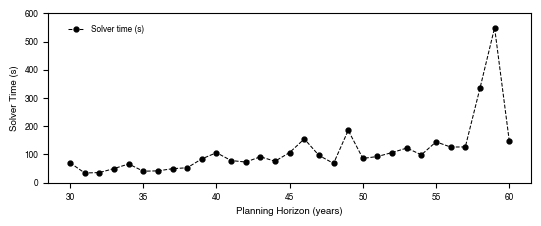

In [23]:
import matplotlib.pyplot as plt

markers = ['o', 'd', 's']
labels = ['SS', 'L2', 'L2upg3', 'L3']
colors = ['#D57A6E', '#B79BB8', '#A3B89C']
hfont = {'fontname':'Helvetica', 'size':7}
hfont_ticks = {'fontname':'Helvetica', 'size':6}
leg_size = 6
line_wid = 0.75
bord_wid = 2
m_size = 3.5
ling_fig_wid = 0.75

import matplotlib.pyplot as plt
import numpy as np

path = '../Results/Sensitivity_all_coordination_years_S/'
dfs_S_years = create_dataframe_computational_cost(path, 'Full_coordination_')


# plot total cost for each WWTP under the trading ratio assumption

fig, ax = plt.subplots(1, 1, figsize=(140/25.4, 60/25.4))
costs = {}
keys = {int(key):key for key in sorted(dfs_S_years.keys())}
set_xticks = sorted(keys.keys())
# create dataframe with rows of keys and column title: solver time and nodes explored
df_comp_cost = pd.DataFrame(index=set_xticks, columns=['Solver_time', 'Nodes_explored', 'Work_units', 'Constraints', 'Variables'])

for key in sorted(keys):
    costs[key] = {}
    df_small = dfs_S_years[keys[key]][['Name', 'Count']]
    df_comp_cost.loc[int(key), 'Solver_time'] = float(df_small[df_small['Name'] == 'Solve Time (s)'].Count.values[0])
    df_comp_cost.loc[int(key), 'Nodes_explored'] = int(df_small[df_small['Name'] == 'B&B Nodes Explored'].Count.values[0])
    df_comp_cost.loc[int(key), 'Work_units'] = float(df_small[df_small['Name'] == 'Work Units'].Count.values[0])
    df_comp_cost.loc[int(key), 'Constraints'] = int(df_small[df_small['Name'] == 'TOTAL Constraints'].Count.values[0])
    df_comp_cost.loc[int(key), 'Variables'] = int(df_small[df_small['Name'] == 'TOTAL Variables'].Count.values[0])
    #print(f"Key: {key}, Solver Time: {df_comp_cost.loc[int(key), 'Solver_time']}s, Nodes Explored: {df_comp_cost.loc[int(key), 'Nodes_explored']}, Work Units: {df_comp_cost.loc[int(key), 'Work_units']}, Constraints: {df_comp_cost.loc[int(key), 'Constraints']}, Variables: {df_comp_cost.loc[int(key), 'Variables']}")

# plot total cost for each WWTP
ax.plot(df_comp_cost.index, df_comp_cost['Solver_time'], label='Solver time (s)', marker='o', color='black', linestyle='--', linewidth=line_wid, markersize=m_size)
#ax.plot(df_comp_cost.index, df_comp_cost['Work_units'], label='Work units', marker='o', color='black', linestyle='--', linewidth=line_wid, markersize=m_size)
    
ax.set_ylim(0, 250)
ax.set_xlabel('Planning Horizon (years)', **hfont)
ax.set_ylabel('Solver Time (s)', **hfont)
#set both label ticks to **hfont_ticks
set_xticks_labels = [x for x in set_xticks[::5]]
ax.set_xticks(set_xticks_labels, set_xticks_labels, **hfont_ticks)
ax.set_yticks(range(0, 601, 100), range(0, 601, 100), **hfont_ticks)

ax.legend(prop = {'family':'Helvetica', 'size':leg_size}, loc='upper left', frameon=False, bbox_to_anchor=(0.025, 0.975), ncol = 1)
plt.tight_layout()
plt.show()
fig.savefig(file + "/SI/S14.svg", format="svg", bbox_inches='tight', dpi=300)

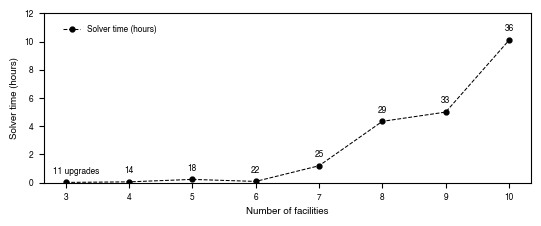

In [22]:
import matplotlib.pyplot as plt

markers = ['o', 'd', 's']
labels = ['SS', 'L2', 'L2upg3', 'L3']
colors = ['#D57A6E', '#B79BB8', '#A3B89C']
hfont = {'fontname':'Helvetica', 'size':7}
hfont_ticks = {'fontname':'Helvetica', 'size':6}
leg_size = 6
line_wid = 0.75
bord_wid = 2
m_size = 3.5
ling_fig_wid = 0.75

import matplotlib.pyplot as plt
import numpy as np
path = '../Results/Sensitivity_all_coordination_PlantNumb_S/'
dfs_S_plantnumb = create_dataframe_computational_cost(path, 'Full_coordination_')


upg_per_plant = {'Palo Alto': 3, 'SJSC': 4, 'Sunnyvale': 4}
PA_copies = 1; SJSC_copies = 1; Sunnyvale_copies = 1

# plot total cost for each WWTP under the trading ratio assumption

fig, ax = plt.subplots(1, 1, figsize=(140/25.4, 60/25.4))
costs = {}
keys = {int(key):key for key in sorted(dfs_S_plantnumb.keys())}
set_xticks = sorted(keys.keys())
# create dataframe with rows of keys and column title: solver time and nodes explored
df_comp_cost_plant_numb = pd.DataFrame(index=set_xticks, columns=['Solver_time', 'Nodes_explored', 'Work_units', 'Constraints', 'Variables', 'Upgrade_number'])

for key in sorted(keys):
    n_original = 3
    extra = int(key) - n_original # since the original model has 3 plants
    source_idx = extra % n_original          # cycles through 0, 1, 2, 0, 1, 2 ...

    if key > n_original:
        PA_copies = PA_copies + 1 if source_idx == 1 else PA_copies
        SJSC_copies = SJSC_copies + 1 if source_idx == 2 else SJSC_copies
        Sunnyvale_copies = Sunnyvale_copies + 1 if source_idx == 0 else Sunnyvale_copies
    numb_upgrades = PA_copies * upg_per_plant['Palo Alto'] + SJSC_copies * upg_per_plant['SJSC'] + Sunnyvale_copies * upg_per_plant['Sunnyvale']
    
    df_small = dfs_S_plantnumb[keys[key]][['Name', 'Count']]
    df_comp_cost_plant_numb.loc[int(key), 'Solver_time'] = float(df_small[df_small['Name'] == 'Solve Time (s)'].Count.values[0])
    df_comp_cost_plant_numb.loc[int(key), 'Nodes_explored'] = int(df_small[df_small['Name'] == 'B&B Nodes Explored'].Count.values[0])
    df_comp_cost_plant_numb.loc[int(key), 'Work_units'] = float(df_small[df_small['Name'] == 'Work Units'].Count.values[0])
    df_comp_cost_plant_numb.loc[int(key), 'Constraints'] = int(df_small[df_small['Name'] == 'TOTAL Constraints'].Count.values[0])
    df_comp_cost_plant_numb.loc[int(key), 'Variables'] = int(df_small[df_small['Name'] == 'TOTAL Variables'].Count.values[0])
    df_comp_cost_plant_numb.loc[int(key), 'Upgrade_number'] = numb_upgrades

# plot total cost for each WWTP
ax.plot(df_comp_cost_plant_numb.index, df_comp_cost_plant_numb['Solver_time']/3600, label='Solver time (hours)', marker='o', color='black', linestyle='--', linewidth=line_wid, markersize=m_size)
#ax.plot(df_comp_cost_plant_numb.index, df_comp_cost_plant_numb['Work_units']/1000, label='Solver time (hours)', marker='o', color='black', linestyle='--', linewidth=line_wid, markersize=m_size)

# add text next to each data point with number of upgrades
#"""
for i, row in df_comp_cost_plant_numb.iterrows():
    if i == 3:
        ax.text(i- 0.2, row['Solver_time']/3600 + 0.5, f"{row['Upgrade_number']} upgrades", fontsize=6, ha='left', va='bottom', fontname='Helvetica')
    else:
        ax.text(i, row['Solver_time']/3600+ 0.5, f"{row['Upgrade_number']}", fontsize=6, ha='center', va='bottom', fontname='Helvetica')    
#"""        

ax.set_ylim(0, 12)
#ax.set_ylim(0, 100)
ax.set_xlabel('Number of facilities', **hfont)
ax.set_ylabel('Solver time (hours)', **hfont)
#set both label ticks to **hfont_ticks
ax.set_xticks(set_xticks, set_xticks, **hfont_ticks)
ax.set_yticks(range(0, 13, 2), range(0, 13, 2), **hfont_ticks)

ax.legend(prop = {'family':'Helvetica', 'size':leg_size}, loc='upper left', frameon=False, bbox_to_anchor=(0.025, 0.975), ncol = 1)
plt.tight_layout()
plt.show()
fig.savefig(file + "/SI/S13.svg", format="svg", bbox_inches='tight', dpi=300)

# Comparing load-based vs flow-based costing

Summary: No_coordination_summary.csv
Total cost for S-NC: 477, 480 | percent difference between load and flow: 0.6%
Summary: Partial_coordination_summary.csv
Total cost for S-PC: 469, 468 | percent difference between load and flow: -0.3%
Summary: Full_coordination_summary.csv
Total cost for S-FC: 294, 294 | percent difference between load and flow: -0.0%
Summary: No_coordination_summary.csv
Total cost for NS-NC: 562, 565 | percent difference between load and flow: 0.7%
Summary: Partial_coordination_summary.csv
Total cost for NS-PC: 553, 551 | percent difference between load and flow: -0.3%
Summary: Full_coordination_summary.csv
Total cost for NS-FC: 331, 331 | percent difference between load and flow: -0.0%


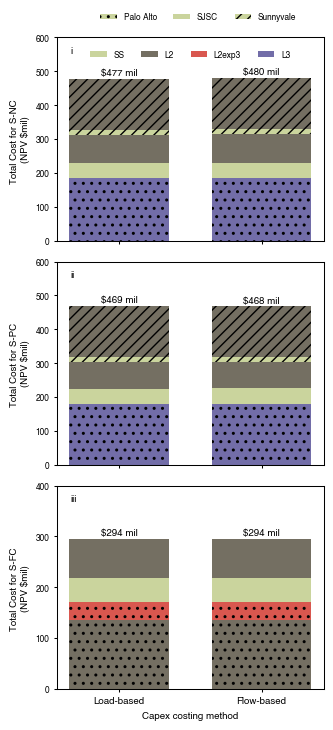

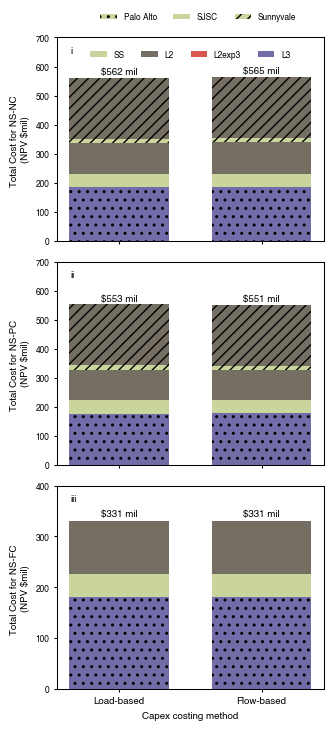

In [19]:
WWTPs = ['Palo Alto', 'SJSC', 'Sunnyvale']

colors = {'L3': '#726DA8', 'L2': '#746F62', 'SS': '#CAD49D', 'L2upg3': '#D9574F', 'total': '#EB5E28', 'required': '#8EA8C3'}
capex_col = ['SS_capex_NPV', 'L2_capex_NPV', 'L2upg3_capex_NPV', 'L3_capex_NPV']
opex_col = ['SS_opex_NPV', 'L2_opex_NPV', 'L2upg3_opex_NPV', 'L3_opex_NPV']
L_labels = ['SS', 'L2', 'L2upg3', 'L3']
hatch_style = ['..','','///']


hfont = {'fontname':'Helvetica', 'size':7}
hfont_ticks = {'fontname':'Helvetica', 'size':6}
lab_size = 7
leg_size = 6
line_wid = 0.75
bord_wid = 2
m_size = 2.5

staged_tag = 'S'
sub_lab = ['i', 'ii', 'iii']

for staged_tag in ['S', 'NS']:

    if staged_tag == 'S':
        path_load = '../Results/Staged/'
        path_flow = '../Results/Staged_flow_costing/'
        summary_cases = ['S-NC', 'S-PC', 'S-FC']
        y_max = [600, 600, 400]
        file_name = "/SI/S16a.svg"
        
    elif staged_tag == 'NS':
        path_load = '../Results/Non_Staged/'
        path_flow = '../Results/Non_Staged_flow_costing/'
        summary_cases = ['NS-NC', 'NS-PC', 'NS-FC']
        y_max = [700, 700, 400]
        file_name = "/SI/S16b.svg"
        

    summary_paths = ['No_coordination_summary.csv', 'Partial_coordination_summary.csv', 'Full_coordination_summary.csv']


    #create figure with 3 subplots

    fig, axs = plt.subplots(len(summary_paths),1, figsize=(80/25.4, 180/25.4))

    # Plot Case 2: non-coordinated
    for j, summary in enumerate(summary_paths):
        print(f'Summary: {summary}')
        dfs_capex = {}
        for key in ['load', 'flow']:
            dfs_capex[f'{key}'] = pd.read_csv(globals()[f'path_{key}'] + summary)
        cumval = 0
        desired_indices = dfs_capex.keys()
        for i,WWTP in enumerate(WWTPs):
            df = create_df(WWTP, dfs_capex)
            df = df.loc[desired_indices]
            upgrades = pd.DataFrame()
            for L,column in enumerate(capex_col):
                upgrades[L_labels[L]] = df[capex_col[L]] + df[opex_col[L]]
                axs[j].bar(desired_indices, upgrades[L_labels[L]], label = WWTP + L_labels[L], color=colors[L_labels[L]], hatch = hatch_style[i], bottom = cumval, width = 0.7)
                cumval = cumval + upgrades[L_labels[L]]

        set_xtick_labels = ['Load-based', 'Flow-based']
        axs[j].set_xticks([str(key) for key in dfs_capex.keys()])
        axs[j].set_xticklabels(set_xtick_labels, **hfont_ticks)
        axs[j].set_xticklabels([' ', ' '], **hfont_ticks)
        axs[j].set_ylabel(f'Total Cost for {summary_cases[j]} \n(NPV $mil)', **hfont)
        if j > 1:
            axs[j].set_xlabel('Capex costing method', **hfont)
            axs[j].set_xticklabels(set_xtick_labels, **hfont_ticks)
            


        if j == 0:
            handles, labels = axs[j].get_legend_handles_labels()
            selected_labels = ['SJSCSS', 'SJSCL2', 'SJSCL2upg3', 'SJSCL3']
            selected_handles = [handles[labels.index(lbl)] for lbl in selected_labels]

            selected_labels_WWTPs = ['Palo AltoSS', 'SJSCSS', 'SunnyvaleSS']
            selected_handles_WWTPs = [handles[labels.index(lbl)] for lbl in selected_labels_WWTPs]
            axs[j].legend(
                selected_handles,
                ['SS', 'L2', 'L2exp3', 'L3'],
                loc="upper center",    # Position the legend at the top center
                bbox_to_anchor=(0.5, 0.975),  # Fine-tune the position above the figure
                ncol=4,                # Display items in a single row
                prop={'family':'Helvetica', 'size':leg_size},  # Set font to Helvetica
                frameon=False
            )

            fig.legend(
                selected_handles_WWTPs,
                ['Palo Alto', 'SJSC', 'Sunnyvale'],
                loc="upper center",    # Position the legend at the top center
                bbox_to_anchor=(0.6, 1.01),  # Fine-tune the position above the figure
                ncol=3,                # Display items in a single row
                prop={'family':'Helvetica', 'size':leg_size},  # Set font to Helvetica
                frameon=False
            )

        # add only sum of total height as text on top of the last bar for each group
        for i, group in enumerate(desired_indices):
            total_height = cumval[group]
            cost_text = f'${total_height:.0f} mil'
            axs[j].text(group, total_height + 5, cost_text, fontsize=7, ha='center', va='bottom', fontname='Helvetica')
        print(f'Total cost for {summary_cases[j]}: {cumval.iloc[0]:.0f}, {cumval.iloc[1]:.0f} | percent difference between load and flow: {((cumval.iloc[1] - cumval.iloc[0]) / cumval.iloc[0] * 100):.1f}%')

        
        axs[j].tick_params(axis="both", width=line_wid, length=bord_wid, labelsize=leg_size)
        axs[j].tick_params(axis='both', labelsize=lab_size)
        axs[j].set_ylim([0, y_max[j]])
        axs[j].set_yticks(range(0, y_max[j]+1, 100))
        axs[j].set_yticklabels(range(0, y_max[j]+1, 100), **hfont_ticks)

        for spine in axs[j].spines.values():
            spine.set_linewidth(line_wid)  # Adjust thickness (default is ~1.0)

    for i in range(len(summary_paths)):
        axs[i].text(0.05, 0.925, sub_lab[i], transform=axs[i].transAxes, fontsize=lab_size, fontname='Helvetica', fontweight='bold')
    
    fig.tight_layout(pad=0.05, rect=[0, 0, 1, 0.97])
    fig.savefig(file + file_name, format="svg", bbox_inches='tight', dpi=300)

Summary: No_coordination_summary.csv
Total cost for S-NC: 477, 471 | percent difference between linear and exponential projection: -1.3%
Summary: Partial_coordination_summary.csv
Total cost for S-PC: 469, 462 | percent difference between linear and exponential projection: -1.6%
Summary: Full_coordination_summary.csv
Total cost for S-FC: 294, 278 | percent difference between linear and exponential projection: -5.6%
Summary: No_coordination_summary.csv
Total cost for NS-NC: 562, 547 | percent difference between linear and exponential projection: -2.6%
Summary: Partial_coordination_summary.csv
Total cost for NS-PC: 553, 537 | percent difference between linear and exponential projection: -2.9%
Summary: Full_coordination_summary.csv
Total cost for NS-FC: 331, 323 | percent difference between linear and exponential projection: -2.3%


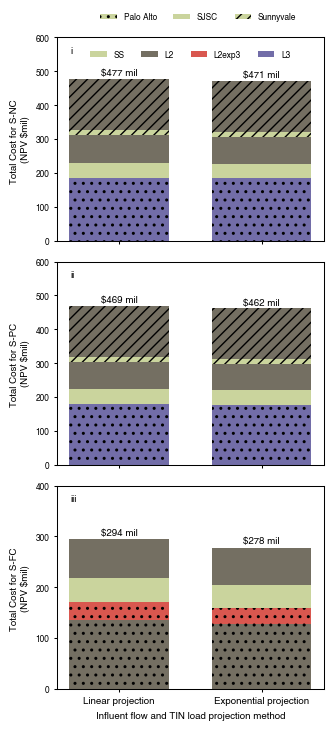

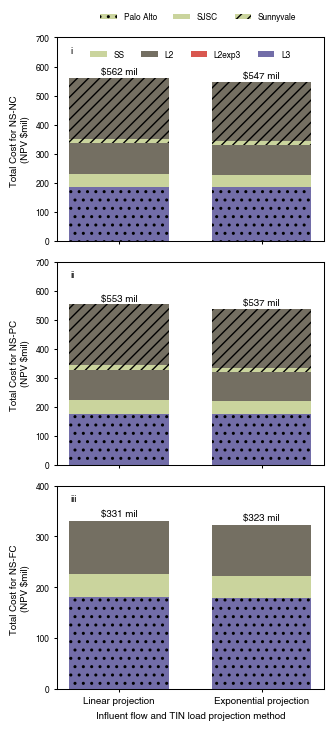

In [20]:
WWTPs = ['Palo Alto', 'SJSC', 'Sunnyvale']

colors = {'L3': '#726DA8', 'L2': '#746F62', 'SS': '#CAD49D', 'L2upg3': '#D9574F', 'total': '#EB5E28', 'required': '#8EA8C3'}
capex_col = ['SS_capex_NPV', 'L2_capex_NPV', 'L2upg3_capex_NPV', 'L3_capex_NPV']
opex_col = ['SS_opex_NPV', 'L2_opex_NPV', 'L2upg3_opex_NPV', 'L3_opex_NPV']
L_labels = ['SS', 'L2', 'L2upg3', 'L3']
hatch_style = ['..','','///']


hfont = {'fontname':'Helvetica', 'size':7}
hfont_ticks = {'fontname':'Helvetica', 'size':6}
lab_size = 7
leg_size = 6
line_wid = 0.75
bord_wid = 2
m_size = 2.5

staged_tag = 'S'

for staged_tag in ['S', 'NS']:

    if staged_tag == 'S':
        path_linear = '../Results/Staged/'
        path_exponential = '../Results/Exponential_projection_S/'
        summary_cases = ['S-NC', 'S-PC', 'S-FC']
        y_max = [600, 600, 400]
        file_name = "/SI/S19a.svg"
    elif staged_tag == 'NS':
        path_linear = '../Results/Non_Staged/'
        path_exponential = '../Results/Exponential_projection_NS/'
        summary_cases = ['NS-NC', 'NS-PC', 'NS-FC']
        y_max = [700, 700, 400]
        file_name = "/SI/S19b.svg"

    summary_paths = ['No_coordination_summary.csv', 'Partial_coordination_summary.csv', 'Full_coordination_summary.csv']


    #create figure with 3 subplots

    fig, axs = plt.subplots(len(summary_paths),1, figsize=(80/25.4, 180/25.4))

    # Plot Case 2: non-coordinated
    for j, summary in enumerate(summary_paths):
        print(f'Summary: {summary}')
        dfs_capex = {}
        for key in ['linear', 'exponential']:
            dfs_capex[f'{key}'] = pd.read_csv(globals()[f'path_{key}'] + summary)
        cumval = 0
        desired_indices = dfs_capex.keys()
        for i,WWTP in enumerate(WWTPs):
            df = create_df(WWTP, dfs_capex)
            df = df.loc[desired_indices]
            upgrades = pd.DataFrame()
            for L,column in enumerate(capex_col):
                upgrades[L_labels[L]] = df[capex_col[L]] + df[opex_col[L]]
                axs[j].bar(desired_indices, upgrades[L_labels[L]], label = WWTP + L_labels[L], color=colors[L_labels[L]], hatch = hatch_style[i], bottom = cumval, width = 0.7)
                cumval = cumval + upgrades[L_labels[L]]

        set_xtick_labels = ['Linear projection', 'Exponential projection']
        axs[j].set_xticks([str(key) for key in dfs_capex.keys()])
        axs[j].set_xticklabels(set_xtick_labels, **hfont_ticks)
        axs[j].set_xticklabels([' ', ' '], **hfont_ticks)
        axs[j].set_ylabel(f'Total Cost for {summary_cases[j]} \n(NPV $mil)', **hfont)
        if j > 1:
            axs[j].set_xlabel('Influent flow and TIN load projection method', **hfont)
            axs[j].set_xticklabels(set_xtick_labels, **hfont_ticks)
            


        if j == 0:
            handles, labels = axs[j].get_legend_handles_labels()
            selected_labels = ['SJSCSS', 'SJSCL2', 'SJSCL2upg3', 'SJSCL3']
            selected_handles = [handles[labels.index(lbl)] for lbl in selected_labels]

            selected_labels_WWTPs = ['Palo AltoSS', 'SJSCSS', 'SunnyvaleSS']
            selected_handles_WWTPs = [handles[labels.index(lbl)] for lbl in selected_labels_WWTPs]
            axs[j].legend(
                selected_handles,
                ['SS', 'L2', 'L2exp3', 'L3'],
                loc="upper center",    # Position the legend at the top center
                bbox_to_anchor=(0.5, 0.975),  # Fine-tune the position above the figure
                ncol=4,                # Display items in a single row
                prop={'family':'Helvetica', 'size':leg_size},  # Set font to Helvetica
                frameon=False
            )

            fig.legend(
                selected_handles_WWTPs,
                ['Palo Alto', 'SJSC', 'Sunnyvale'],
                loc="upper center",    # Position the legend at the top center
                bbox_to_anchor=(0.6, 1.01),  # Fine-tune the position above the figure
                ncol=3,                # Display items in a single row
                prop={'family':'Helvetica', 'size':leg_size},  # Set font to Helvetica
                frameon=False
            )

        # add only sum of total height as text on top of the last bar for each group
        for i, group in enumerate(desired_indices):
            total_height = cumval[group]
            cost_text = f'${total_height:.0f} mil'
            axs[j].text(group, total_height + 5, cost_text, fontsize=7, ha='center', va='bottom', fontname='Helvetica')
        print(f'Total cost for {summary_cases[j]}: {cumval.iloc[0]:.0f}, {cumval.iloc[1]:.0f} | percent difference between linear and exponential projection: {((cumval.iloc[1] - cumval.iloc[0]) / cumval.iloc[0] * 100):.1f}%')

        
        axs[j].tick_params(axis="both", width=line_wid, length=bord_wid, labelsize=leg_size)
        axs[j].tick_params(axis='both', labelsize=lab_size)
        axs[j].set_ylim([0, y_max[j]])
        axs[j].set_yticks(range(0, y_max[j]+1, 100))
        axs[j].set_yticklabels(range(0, y_max[j]+1, 100), **hfont_ticks)

        for spine in axs[j].spines.values():
            spine.set_linewidth(line_wid)  # Adjust thickness (default is ~1.0)

    for i in range(len(summary_paths)):
        axs[i].text(0.05, 0.925, sub_lab[i], transform=axs[i].transAxes, fontsize=lab_size, fontname='Helvetica', fontweight='bold')
        
    fig.tight_layout(pad=0.05, rect=[0, 0, 1, 0.97])
    fig.savefig(file + file_name, format="svg", bbox_inches='tight', dpi=300)

Summary: No_coordination_summary.csv
Total cost for S-NC: 477, 475 | percent difference between linear and exponential projection: -0.4%
Summary: Partial_coordination_summary.csv
Total cost for S-PC: 469, 468 | percent difference between linear and exponential projection: -0.4%
Summary: Full_coordination_summary.csv
Total cost for S-FC: 294, 293 | percent difference between linear and exponential projection: -0.4%
Summary: No_coordination_summary.csv
Total cost for NS-NC: 562, 559 | percent difference between linear and exponential projection: -0.5%
Summary: Partial_coordination_summary.csv
Total cost for NS-PC: 553, 551 | percent difference between linear and exponential projection: -0.4%
Summary: Full_coordination_summary.csv
Total cost for NS-FC: 331, 330 | percent difference between linear and exponential projection: -0.2%


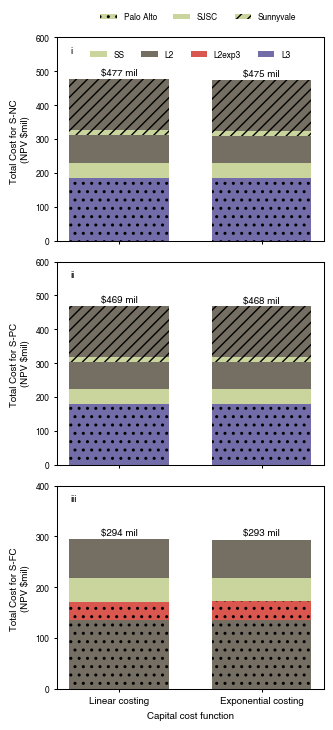

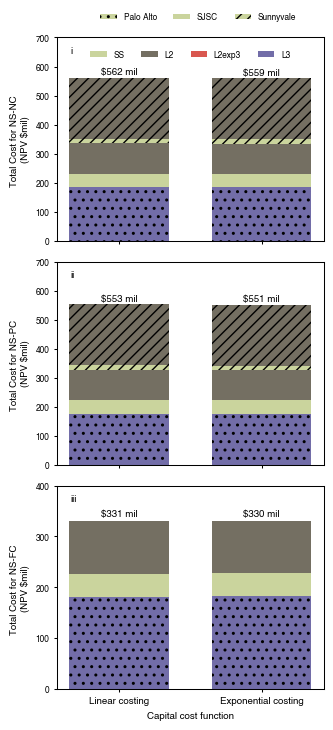

In [21]:
WWTPs = ['Palo Alto', 'SJSC', 'Sunnyvale']

colors = {'L3': '#726DA8', 'L2': '#746F62', 'SS': '#CAD49D', 'L2upg3': '#D9574F', 'total': '#EB5E28', 'required': '#8EA8C3'}
max_flow_col = ['SS_x_flow_max', 'L2_x_flow_max', 'L2upg3_x_flow_max', 'L3_x_flow_max']
capex_col = ['SS_capex_NPV', 'L2_capex_NPV', 'L2upg3_capex_NPV', 'L3_capex_NPV']
opex_col = ['SS_opex_NPV', 'L2_opex_NPV', 'L2upg3_opex_NPV', 'L3_opex_NPV']
L_labels = ['SS', 'L2', 'L2upg3', 'L3']
hatch_style = ['..','','///']


hfont = {'fontname':'Helvetica', 'size':7}
hfont_ticks = {'fontname':'Helvetica', 'size':6}
lab_size = 7
leg_size = 6
line_wid = 0.75
bord_wid = 2
m_size = 2.5

staged_tag = 'S'

for staged_tag in ['S', 'NS']:

    if staged_tag == 'S':
        path_linear = '../Results/Staged/'
        path_exponential = '../Results/Power_law_S/'
        summary_cases = ['S-NC', 'S-PC', 'S-FC']
        y_max = [600, 600, 400]
        file_name = "/SI/S21a.svg"
    elif staged_tag == 'NS':
        path_linear = '../Results/Non_Staged/'
        path_exponential = '../Results/Power_law_NS/'
        summary_cases = ['NS-NC', 'NS-PC', 'NS-FC']
        y_max = [700, 700, 400]
        file_name = "/SI/S21b.svg"

    summary_paths = ['No_coordination_summary.csv', 'Partial_coordination_summary.csv', 'Full_coordination_summary.csv']


    #create figure with 3 subplots

    fig, axs = plt.subplots(len(summary_paths),1, figsize=(80/25.4, 180/25.4))

    # Plot Case 2: non-coordinated
    for j, summary in enumerate(summary_paths):
        print(f'Summary: {summary}')
        dfs_capex = {}
        for key in ['linear', 'exponential']:
            dfs_capex[f'{key}'] = pd.read_csv(globals()[f'path_{key}'] + summary)
        cumval = 0
        desired_indices = dfs_capex.keys()
        for i,WWTP in enumerate(WWTPs):
            df = create_df(WWTP, dfs_capex)
            df = df.loc[desired_indices]
            upgrades = pd.DataFrame()
            for L,column in enumerate(capex_col):
                upgrades[L_labels[L]] = df[capex_col[L]] + df[opex_col[L]]
                axs[j].bar(desired_indices, upgrades[L_labels[L]], label = WWTP + L_labels[L], color=colors[L_labels[L]], hatch = hatch_style[i], bottom = cumval, width = 0.7)
                cumval = cumval + upgrades[L_labels[L]]

        set_xtick_labels = ['Linear costing', 'Exponential costing']
        axs[j].set_xticks([str(key) for key in dfs_capex.keys()])
        axs[j].set_xticklabels(set_xtick_labels, **hfont_ticks)
        axs[j].set_xticklabels([' ', ' '], **hfont_ticks)
        axs[j].set_ylabel(f'Total Cost for {summary_cases[j]} \n(NPV $mil)', **hfont)
        if j > 1:
            axs[j].set_xlabel('Capital cost function', **hfont)
            axs[j].set_xticklabels(set_xtick_labels, **hfont_ticks)
            


        if j == 0:
            handles, labels = axs[j].get_legend_handles_labels()
            selected_labels = ['SJSCSS', 'SJSCL2', 'SJSCL2upg3', 'SJSCL3']
            selected_handles = [handles[labels.index(lbl)] for lbl in selected_labels]

            selected_labels_WWTPs = ['Palo AltoSS', 'SJSCSS', 'SunnyvaleSS']
            selected_handles_WWTPs = [handles[labels.index(lbl)] for lbl in selected_labels_WWTPs]
            axs[j].legend(
                selected_handles,
                ['SS', 'L2', 'L2exp3', 'L3'],
                loc="upper center",    # Position the legend at the top center
                bbox_to_anchor=(0.5, 0.975),  # Fine-tune the position above the figure
                ncol=4,                # Display items in a single row
                prop={'family':'Helvetica', 'size':leg_size},  # Set font to Helvetica
                frameon=False
            )

            fig.legend(
                selected_handles_WWTPs,
                ['Palo Alto', 'SJSC', 'Sunnyvale'],
                loc="upper center",    # Position the legend at the top center
                bbox_to_anchor=(0.6, 1.01),  # Fine-tune the position above the figure
                ncol=3,                # Display items in a single row
                prop={'family':'Helvetica', 'size':leg_size},  # Set font to Helvetica
                frameon=False
            )

        # add only sum of total height as text on top of the last bar for each group
        for i, group in enumerate(desired_indices):
            total_height = cumval[group]
            cost_text = f'${total_height:.0f} mil'
            axs[j].text(group, total_height + 5, cost_text, fontsize=7, ha='center', va='bottom', fontname='Helvetica')
        print(f'Total cost for {summary_cases[j]}: {cumval.iloc[0]:.0f}, {cumval.iloc[1]:.0f} | percent difference between linear and exponential projection: {((cumval.iloc[1] - cumval.iloc[0]) / cumval.iloc[0] * 100):.1f}%')

        
        axs[j].tick_params(axis="both", width=line_wid, length=bord_wid, labelsize=leg_size)
        axs[j].tick_params(axis='both', labelsize=lab_size)
        axs[j].set_ylim([0, y_max[j]])
        axs[j].set_yticks(range(0, y_max[j]+1, 100))
        axs[j].set_yticklabels(range(0, y_max[j]+1, 100), **hfont_ticks)

        for spine in axs[j].spines.values():
            spine.set_linewidth(line_wid)  # Adjust thickness (default is ~1.0)

    for i in range(len(summary_paths)):
        axs[i].text(0.05, 0.925, sub_lab[i], transform=axs[i].transAxes, fontsize=lab_size, fontname='Helvetica', fontweight='bold')
        
    fig.tight_layout(pad=0.05, rect=[0, 0, 1, 0.97])
    fig.savefig(file + file_name, format="svg", bbox_inches='tight', dpi=300)